<a href="https://colab.research.google.com/github/Beebah-rahman09/inorganic-materials-band-gap-prediction/blob/main/Project_01_Machine_Learning_Materials_Discovery.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

# PROJECT 01
# Machine Learning-Based Prediction of Electronic Band Gaps
# Researcher: Habiba Abdulrahman Abdullahi

import sys
import platform

project_title = (
    "Machine Learning-Based Prediction of Electronic "
    "Band Gaps in Inorganic Materials"
)

research_question = (
    "Can machine learning models predict the electronic "
    "band gaps of inorganic materials?"
)

research_objectives = [
    "Understand the scientific meaning of electronic band gaps.",
    "Explore an established materials science dataset.",
    "Prepare and analyse scientific data.",
    "Train and evaluate machine learning models.",
    "Interpret the results and their scientific limitations."
]

print("RESEARCH PROJECT 01")
print("=" * 45)
print("Title:", project_title)
print("\nResearch question:", research_question)

print("\nResearch objectives:")
for number, objective in enumerate(research_objectives, 1):
    print(f"{number}. {objective}")

print("\nPython version:", sys.version)
print("Platform:", platform.platform())

print("\nResearch environment successfully started!")


RESEARCH PROJECT 01
Title: Machine Learning-Based Prediction of Electronic Band Gaps in Inorganic Materials

Research question: Can machine learning models predict the electronic band gaps of inorganic materials?

Research objectives:
1. Understand the scientific meaning of electronic band gaps.
2. Explore an established materials science dataset.
3. Prepare and analyse scientific data.
4. Train and evaluate machine learning models.
5. Interpret the results and their scientific limitations.

Python version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Platform: Linux-6.6.159+-x86_64-with-glibc2.39

Research environment successfully started!


In [ ]:
import sys
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt

print("Python version:", sys.version)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

print("\nOur research environment is ready!")

Python version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
NumPy: 2.1.3
Pandas: 2.2.3
Scikit-learn: 1.6.1

Our research environment is ready!


In [ ]:
research_notes = {
    "property": "Electronic band gap",
    "measurement": "Electronvolts (eV)",
    "dataset": "MatBench matbench_mp_gap",
    "number_of_entries": 106113,
    "research_method": "Supervised machine learning",
    "main_goal": "Predict electronic band gaps"
}

print("PROJECT 01: SCIENTIFIC BACKGROUND")
print("=" * 45)

for key, value in research_notes.items():
    print(f"{key.replace('_', ' ').title()}: {value}")

PROJECT 01: SCIENTIFIC BACKGROUND
Property: Electronic band gap
Measurement: Electronvolts (eV)
Dataset: MatBench matbench_mp_gap
Number Of Entries: 106113
Research Method: Supervised machine learning
Main Goal: Predict electronic band gaps


In [ ]:
import pandas as pd

url = "https://raw.githubusercontent.com/materialsproject/matbench/main/matbench/data/megnet_structure/mp_gap.csv"

try:
    data = pd.read_csv(url)
    print("Dataset downloaded successfully!")
    print("Dataset shape:", data.shape)
    display(data.head())
except Exception as e:
    print("Download attempt failed:", e)

Download attempt failed: HTTP Error 404: Not Found


In [ ]:
import requests
import gzip
import json

url = "https://ml.materialsproject.org/projects/matbench_mp_gap.json.gz"

response = requests.get(url, timeout=120)
response.raise_for_status()

dataset_bytes = gzip.decompress(response.content)
dataset = json.loads(dataset_bytes.decode("utf-8"))

print("Dataset downloaded successfully!")
print("Data type:", type(dataset))

if isinstance(dataset, dict):
    print("Available fields:", list(dataset.keys()))
elif isinstance(dataset, list):
    print("Number of records:", len(dataset))
    print("First record:", dataset[0])

Dataset downloaded successfully!
Data type: <class 'dict'>
Available fields: ['index', 'columns', 'data']


In [ ]:
import pandas as pd

df = pd.DataFrame(
    dataset["data"],
    columns=dataset["columns"],
    index=dataset["index"]
)

print("Dataset successfully converted!")
print("\nDataset dimensions:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five records:")
display(df.head())

Dataset successfully converted!

Dataset dimensions: (106113, 2)

Column names:
['structure', 'gap pbe']

First five records:


,structure,gap pbe
0,"{'@module': 'pymatgen.core.structure', '@class...",1.3322
1,"{'@module': 'pymatgen.core.structure', '@class...",0.0000
2,"{'@module': 'pymatgen.core.structure', '@class...",0.0000
3,"{'@module': 'pymatgen.core.structure', '@class...",0.4113
4,"{'@module': 'pymatgen.core.structure', '@class...",0.3514


In [ ]:
import numpy as np

band_gaps = df["gap pbe"]

print("BAND GAP DATA ANALYSIS")
print("=" * 40)

print("Total materials:", len(band_gaps))
print("Missing values:", band_gaps.isna().sum())
print("Average band gap:", round(band_gaps.mean(), 4), "eV")
print("Median band gap:", round(band_gaps.median(), 4), "eV")
print("Minimum band gap:", round(band_gaps.min(), 4), "eV")
print("Maximum band gap:", round(band_gaps.max(), 4), "eV")
print("Standard deviation:", round(band_gaps.std(), 4), "eV")

print("\nNumber of zero-band-gap materials:",
      (band_gaps == 0).sum())

print("Number of positive-band-gap materials:",
      (band_gaps > 0).sum())

BAND GAP DATA ANALYSIS
Total materials: 106113
Missing values: 0
Average band gap: 1.2146 eV
Median band gap: 0.2738 eV
Minimum band gap: 0.0 eV
Maximum band gap: 9.7212 eV
Standard deviation: 1.599 eV

Number of zero-band-gap materials: 46151
Number of positive-band-gap materials: 59962


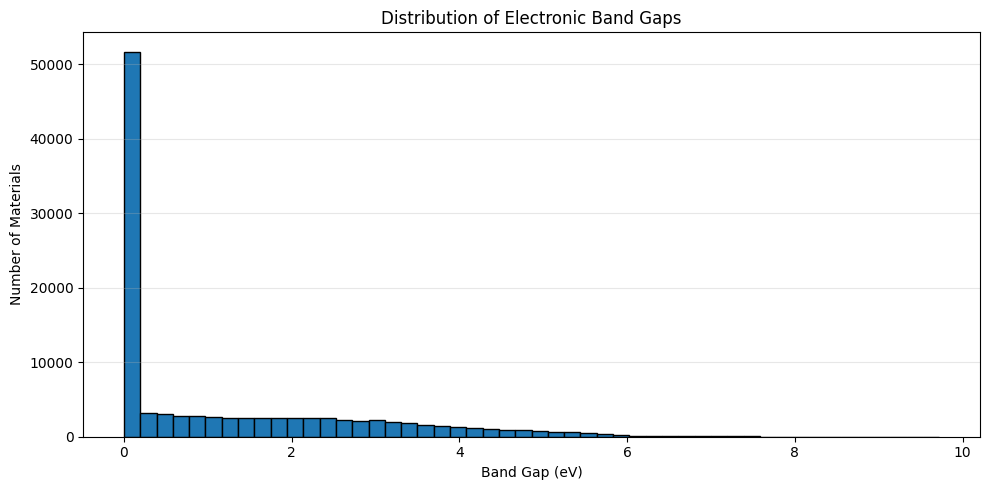

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    df["gap pbe"],
    bins=50,
    edgecolor="black"
)

plt.title("Distribution of Electronic Band Gaps")
plt.xlabel("Band Gap (eV)")
plt.ylabel("Number of Materials")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
graph_interpretation = """
The histogram of electronic band gaps shows a
positively skewed distribution. Most materials
have relatively small band-gap values, while
fewer materials have larger band gaps.

The mean (1.2146 eV) is greater than the
median (0.2738 eV), supporting this observation.
"""

print("SCIENTIFIC INTERPRETATION")
print(graph_interpretation)

SCIENTIFIC INTERPRETATION

The histogram of electronic band gaps shows a
positively skewed distribution. Most materials
have relatively small band-gap values, while
fewer materials have larger band gaps.

The mean (1.2146 eV) is greater than the
median (0.2738 eV), supporting this observation.



In [ ]:
# Select materials with positive band gaps

positive_materials = df[df["gap pbe"] > 0].copy()

print("DATASET PREPARATION")
print("=" * 40)

print("Original dataset:", len(df))
print("Positive-gap materials:", len(positive_materials))
print("Excluded zero-gap materials:",
      len(df) - len(positive_materials))

print("\nMinimum positive band gap:",
      positive_materials["gap pbe"].min())

print("Maximum positive band gap:",
      positive_materials["gap pbe"].max())

print("\nPrepared dataset is ready!")

DATASET PREPARATION
Original dataset: 106113
Positive-gap materials: 59962
Excluded zero-gap materials: 46151

Minimum positive band gap: 9.999999999976694e-05
Maximum positive band gap: 9.721200000000001

Prepared dataset is ready!


In [ ]:
%pip -q install pymatgen

In [ ]:
import pymatgen
import requests

print("Pymatgen version:", pymatgen.__version__)
print("Requests version:", requests.__version__)
print("Materials science library is ready!")

AttributeError: module 'pymatgen' has no attribute '__version__'

In [ ]:
from importlib.metadata import version
import requests

print("Pymatgen version:", version("pymatgen"))
print("Requests version:", requests.__version__)
print("Materials science library is ready!")


Pymatgen version: 2026.10.24
Requests version: 2.32.4
Materials science library is ready!


In [ ]:
from pymatgen.core import Structure
from importlib.metadata import version

print("Pymatgen version:", version("pymatgen"))

example_structure = Structure.from_dict(
    positive_materials.iloc[0]["structure"]
)

print("\nMATERIAL STRUCTURE TEST")
print("=" * 35)

print("Chemical formula:",
      example_structure.composition.reduced_formula)

print("Number of atoms:", len(example_structure))

print("Number of elements:",
      len(example_structure.composition.elements))

print("Elements:",
      [str(e) for e in example_structure.composition.elements])

print("\nPymatgen is working successfully!")

Pymatgen version: 2026.10.24

MATERIAL STRUCTURE TEST
Chemical formula: KMnO2
Number of atoms: 16
Number of elements: 3
Elements: ['K', 'Mn', 'O']

Pymatgen is working successfully!


In [ ]:
import numpy as np
import pandas as pd
from pymatgen.core import Structure

sample = positive_materials.sample(
    n=1000,
    random_state=42
)

features = []

for index, row in sample.iterrows():

    structure = Structure.from_dict(row["structure"])
    elements = structure.composition.elements

    atomic_numbers = np.array([el.Z for el in elements])
    amounts = np.array([
        structure.composition[el] for el in elements
    ])

    atomic_masses = np.array([
        float(el.atomic_mass) for el in elements
    ])

    atomic_fractions = amounts / amounts.sum()

    features.append({
        "number_of_atoms": len(structure),
        "number_of_elements": len(elements),
        "mean_atomic_number": np.average(
            atomic_numbers, weights=atomic_fractions
        ),
        "min_atomic_number": atomic_numbers.min(),
        "max_atomic_number": atomic_numbers.max(),
        "mean_atomic_mass": np.average(
            atomic_masses, weights=atomic_fractions
        ),
        "atomic_number_variation": np.average(
            (atomic_numbers - np.average(
                atomic_numbers, weights=atomic_fractions
            )) ** 2,
            weights=atomic_fractions
        ) ** 0.5
    })

X = pd.DataFrame(features)
y = sample["gap pbe"].reset_index(drop=True)

print("FEATURE EXTRACTION COMPLETE")
print("=" * 40)
print("Materials processed:", len(X))
print("Number of features:", X.shape[1])

display(X.head())

FEATURE EXTRACTION COMPLETE
Materials processed: 1000
Number of features: 7


,number_of_atoms,number_of_elements,mean_atomic_number,min_atomic_number,max_atomic_number,mean_atomic_mass,atomic_number_variation
0,26,5,10.307692,6,24,21.226590,4.529979
1,68,3,34.235294,16,75,78.964941,20.746451
2,4,3,60.500000,52,80,148.500226,11.324752
3,10,4,21.800000,11,65,48.116889,15.131424
4,44,5,7.545455,1,49,15.538436,10.039591


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

# Create the model
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model
model.fit(X_train, y_train)

# Make predictions
predictions = model.predict(X_test)

# Evaluate performance
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("RANDOM FOREST MODEL RESULTS")
print("=" * 40)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Mean Absolute Error:", round(mae, 4), "eV")
print("Root Mean Squared Error:", round(rmse, 4), "eV")
print("R-squared:", round(r2, 4))

RANDOM FOREST MODEL RESULTS
Training samples: 800
Testing samples: 200
Mean Absolute Error: 1.015 eV
Root Mean Squared Error: 1.3675 eV
R-squared: 0.1444


In [ ]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score

# Create a simple baseline model
baseline = DummyRegressor(strategy="mean")

# Train the baseline
baseline.fit(X_train, y_train)

# Make predictions
baseline_predictions = baseline.predict(X_test)

# Calculate baseline performance
baseline_mae = mean_absolute_error(
    y_test, baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_predictions)
)

baseline_r2 = r2_score(
    y_test, baseline_predictions
)

print("MODEL COMPARISON")
print("=" * 45)

print("                    BASELINE    RANDOM FOREST")
print(f"MAE:                {baseline_mae:.4f}      {mae:.4f}")
print(f"RMSE:               {baseline_rmse:.4f}      {rmse:.4f}")
print(f"R-squared:          {baseline_r2:.4f}      {r2:.4f}")

MODEL COMPARISON
                    BASELINE    RANDOM FOREST
MAE:                1.2162      1.0150
RMSE:               1.4818      1.3675
R-squared:          -0.0045      0.1444


FEATURE IMPORTANCE ANALYSIS


,Feature,Importance
4,max_atomic_number,0.258416
6,atomic_number_variation,0.186736
5,mean_atomic_mass,0.146424
2,mean_atomic_number,0.142318
0,number_of_atoms,0.124599
3,min_atomic_number,0.105420
1,number_of_elements,0.036087


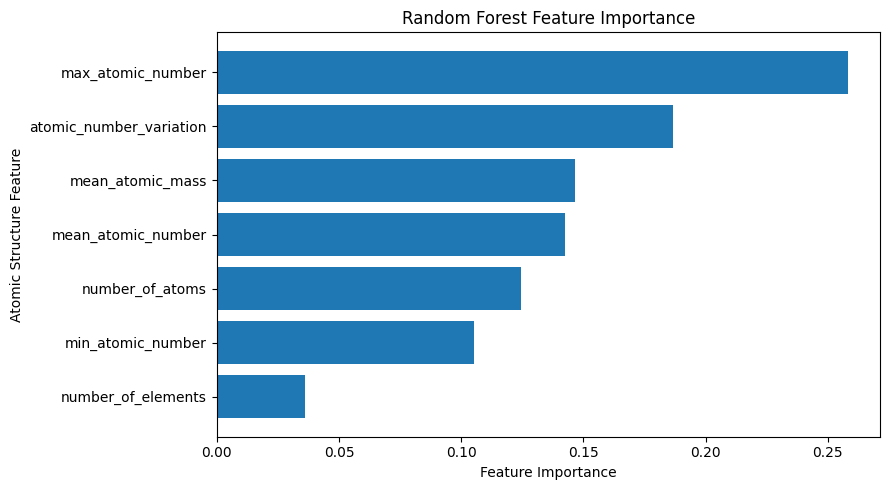

In [ ]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print("FEATURE IMPORTANCE ANALYSIS")
print("=" * 40)

display(importance)

plt.figure(figsize=(9, 5))

plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Atomic Structure Feature")
plt.title("Random Forest Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

FEATURE IMPORTANCE ANALYSIS


,Feature,Importance
4,max_atomic_number,0.258416
6,atomic_number_variation,0.186736
5,mean_atomic_mass,0.146424
2,mean_atomic_number,0.142318
0,number_of_atoms,0.124599
3,min_atomic_number,0.105420
1,number_of_elements,0.036087


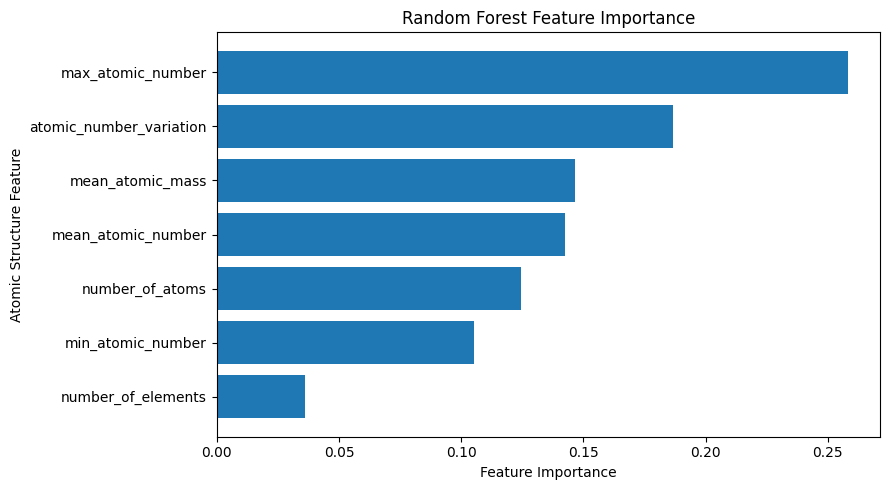

In [ ]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print("FEATURE IMPORTANCE ANALYSIS")
print("=" * 40)

display(importance)

plt.figure(figsize=(9, 5))

plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Atomic Structure Feature")
plt.title("Random Forest Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

FEATURE IMPORTANCE ANALYSIS


,Feature,Importance
4,max_atomic_number,0.258416
6,atomic_number_variation,0.186736
5,mean_atomic_mass,0.146424
2,mean_atomic_number,0.142318
0,number_of_atoms,0.124599
3,min_atomic_number,0.105420
1,number_of_elements,0.036087


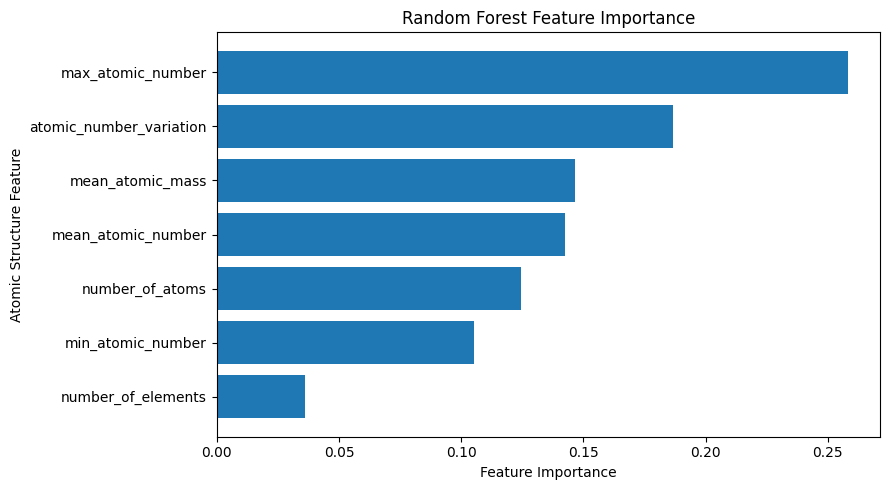

In [ ]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print("FEATURE IMPORTANCE ANALYSIS")
print("=" * 40)

display(importance)

plt.figure(figsize=(9, 5))

plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Atomic Structure Feature")
plt.title("Random Forest Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score

# Create a new model
extra_model = ExtraTreesRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

# Train the model
extra_model.fit(X_train, y_train)

# Make predictions
extra_predictions = extra_model.predict(X_test)

# Evaluate the model
extra_mae = mean_absolute_error(
    y_test, extra_predictions
)

extra_rmse = np.sqrt(
    mean_squared_error(y_test, extra_predictions)
)

extra_r2 = r2_score(y_test, extra_predictions)

print("MODEL IMPROVEMENT EXPERIMENT")
print("=" * 45)

print("Random Forest MAE:", round(mae, 4))
print("Extra Trees MAE:", round(extra_mae, 4))

print("\nRandom Forest RMSE:", round(rmse, 4))
print("Extra Trees RMSE:", round(extra_rmse, 4))

print("\nRandom Forest R2:", round(r2, 4))
print("Extra Trees R2:", round(extra_r2, 4))

MODEL IMPROVEMENT EXPERIMENT
Random Forest MAE: 1.015
Extra Trees MAE: 1.0375

Random Forest RMSE: 1.3675
Extra Trees RMSE: 1.3944

Random Forest R2: 0.1444
Extra Trees R2: 0.1105


In [ ]:
# Select 5,000 positive-gap materials
larger_sample = positive_materials.sample(
    n=5000,
    random_state=42
)

features_large = []

for index, row in larger_sample.iterrows():

    structure = Structure.from_dict(row["structure"])
    elements = structure.composition.elements

    atomic_numbers = np.array([el.Z for el in elements])
    amounts = np.array([
        structure.composition[el] for el in elements
    ])

    atomic_masses = np.array([
        float(el.atomic_mass) for el in elements
    ])

    fractions = amounts / amounts.sum()

    features_large.append({
        "number_of_atoms": len(structure),
        "number_of_elements": len(elements),
        "mean_atomic_number": np.average(
            atomic_numbers, weights=fractions
        ),
        "min_atomic_number": atomic_numbers.min(),
        "max_atomic_number": atomic_numbers.max(),
        "mean_atomic_mass": np.average(
            atomic_masses, weights=fractions
        ),
        "atomic_number_variation": np.average(
            (atomic_numbers - np.average(
                atomic_numbers, weights=fractions
            )
        ) ** 2, weights=fractions) ** 0.5
    })

X_large = pd.DataFrame(features_large)
y_large = larger_sample["gap pbe"].reset_index(drop=True)

print("Larger dataset prepared!")
print("Materials:", len(X_large))
print("Features:", X_large.shape[1])

Larger dataset prepared!
Materials: 5000
Features: 7


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Split the larger dataset
X_train_large, X_test_large, y_train_large, y_test_large = train_test_split(
    X_large,
    y_large,
    test_size=0.20,
    random_state=42
)

# Create and train the model
large_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

large_model.fit(X_train_large, y_train_large)

# Make predictions
large_predictions = large_model.predict(X_test_large)

# Evaluate
large_mae = mean_absolute_error(y_test_large, large_predictions)

large_rmse = np.sqrt(
    mean_squared_error(y_test_large, large_predictions)
)

large_r2 = r2_score(y_test_large, large_predictions)

print("LARGER DATASET MODEL RESULTS")
print("=" * 45)

print("Training materials:", len(X_train_large))
print("Testing materials:", len(X_test_large))
print("MAE:", round(large_mae, 4), "eV")
print("RMSE:", round(large_rmse, 4), "eV")
print("R-squared:", round(large_r2, 4))

LARGER DATASET MODEL RESULTS
Training materials: 4000
Testing materials: 1000
MAE: 0.8972 eV
RMSE: 1.1905 eV
R-squared: 0.4425


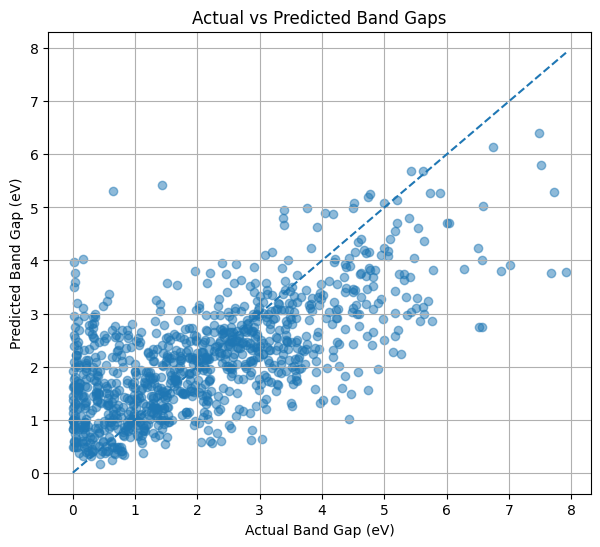

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))

plt.scatter(
    y_test_large,
    large_predictions,
    alpha=0.5
)

plt.plot(
    [0, max(y_test_large)],
    [0, max(y_test_large)],
    linestyle="--"
)

plt.xlabel("Actual Band Gap (eV)")
plt.ylabel("Predicted Band Gap (eV)")
plt.title("Actual vs Predicted Band Gaps")
plt.grid(True)

plt.show()

In [ ]:
mae_improvement = (
    (1.0150 - 0.8972) / 1.0150
) * 100

rmse_improvement = (
    (1.3675 - 1.1905) / 1.3675
) * 100

print(f"MAE improvement: {mae_improvement:.2f}%")
print(f"RMSE improvement: {rmse_improvement:.2f}%")

MAE improvement: 11.61%
RMSE improvement: 12.94%


In [ ]:
import joblib

joblib.dump(large_model, "band_gap_random_forest.pkl")

print("Model saved successfully!")

Model saved successfully!


In [ ]:
results = X_large.copy()

results["actual_band_gap"] = y_large.values
results["predicted_band_gap"] = large_predictions

results.to_csv("band_gap_predictions.csv", index=False)

print("Prediction results saved successfully!")

ValueError: Length of values (1000) does not match length of index (5000)

In [ ]:
import pandas as pd

results = pd.DataFrame({
    "actual_band_gap": y_large.loc[X_test_large.index].values,
    "predicted_band_gap": large_predictions
})

results.to_csv("band_gap_predictions.csv", index=False)
print(results.shape)


(1000, 2)


In [ ]:
import pandas as pd, numpy as np

for name, val in list(globals().items()):
    if name.startswith('_'):
        continue
    if isinstance(val, (pd.DataFrame, pd.Series, np.ndarray)):
        print(name, type(val).__name__, val.shape)


df DataFrame (106113, 2)
band_gaps Series (106113,)
positive_materials DataFrame (59962, 2)
sample DataFrame (1000, 2)
row Series (2,)
atomic_numbers ndarray (5,)
amounts ndarray (5,)
atomic_masses ndarray (5,)
atomic_fractions ndarray (4,)
X DataFrame (1000, 7)
y Series (1000,)
X_train DataFrame (800, 7)
X_test DataFrame (200, 7)
y_train Series (800,)
y_test Series (200,)
predictions ndarray (200,)
baseline_predictions ndarray (200,)
importance DataFrame (7, 2)
extra_predictions ndarray (200,)
larger_sample DataFrame (5000, 2)
fractions ndarray (5,)
X_large DataFrame (5000, 7)
y_large Series (5000,)
X_train_large DataFrame (4000, 7)
X_test_large DataFrame (1000, 7)
y_train_large Series (4000,)
y_test_large Series (1000,)
large_predictions ndarray (1000,)
results DataFrame (5000, 8)


In [ ]:
results = X_test_large.copy()

results["actual_band_gap"] = y_test_large.values
results["predicted_band_gap"] = large_predictions

results.to_csv("band_gap_predictions.csv", index=False)

print("Prediction results saved successfully!")
print("Number of predictions:", len(results))

Prediction results saved successfully!
Number of predictions: 1000


In [ ]:
from google.colab import files

files.download("band_gap_random_forest.pkl")
files.download("band_gap_predictions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd, numpy as np

for name, val in list(globals().items()):
    if name.startswith('_'):
        continue
    if isinstance(val, (pd.DataFrame, pd.Series, np.ndarray)):
        print(name, type(val).__name__, val.shape)


df DataFrame (106113, 2)
band_gaps Series (106113,)
positive_materials DataFrame (59962, 2)
sample DataFrame (1000, 2)
row Series (2,)
atomic_numbers ndarray (5,)
amounts ndarray (5,)
atomic_masses ndarray (5,)
atomic_fractions ndarray (4,)
X DataFrame (1000, 7)
y Series (1000,)
X_train DataFrame (800, 7)
X_test DataFrame (200, 7)
y_train Series (800,)
y_test Series (200,)
predictions ndarray (200,)
baseline_predictions ndarray (200,)
importance DataFrame (7, 2)
extra_predictions ndarray (200,)
larger_sample DataFrame (5000, 2)
fractions ndarray (5,)
X_large DataFrame (5000, 7)
y_large Series (5000,)
X_train_large DataFrame (4000, 7)
X_test_large DataFrame (1000, 7)
y_train_large Series (4000,)
y_test_large Series (1000,)
large_predictions ndarray (1000,)
results DataFrame (1000, 9)


In [ ]:
import pandas as pd, numpy as np

for name, val in list(globals().items()):
    if name.startswith('_'):
        continue
    if isinstance(val, (pd.DataFrame, pd.Series, np.ndarray)):
        print(name, type(val).__name__, val.shape)


df DataFrame (106113, 2)
band_gaps Series (106113,)
positive_materials DataFrame (59962, 2)
sample DataFrame (1000, 2)
row Series (2,)
atomic_numbers ndarray (5,)
amounts ndarray (5,)
atomic_masses ndarray (5,)
atomic_fractions ndarray (4,)
X DataFrame (1000, 7)
y Series (1000,)
X_train DataFrame (800, 7)
X_test DataFrame (200, 7)
y_train Series (800,)
y_test Series (200,)
predictions ndarray (200,)
baseline_predictions ndarray (200,)
importance DataFrame (7, 2)
extra_predictions ndarray (200,)
larger_sample DataFrame (5000, 2)
fractions ndarray (5,)
X_large DataFrame (5000, 7)
y_large Series (5000,)
X_train_large DataFrame (4000, 7)
X_test_large DataFrame (1000, 7)
y_train_large Series (4000,)
y_test_large Series (1000,)
large_predictions ndarray (1000,)
results DataFrame (1000, 9)


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, cross_validate
import numpy as np

cv = KFold(n_splits=5, shuffle=True, random_state=42)
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)

scores = cross_validate(
    rf, X_large, y_large, cv=cv,
    scoring=("neg_mean_absolute_error",
             "neg_root_mean_squared_error",
             "r2")
)

mae  = -scores["test_neg_mean_absolute_error"]
rmse = -scores["test_neg_root_mean_squared_error"]
r2   = scores["test_r2"]

print(f"MAE : {mae.mean():.4f} ± {mae.std():.4f} eV")
print(f"RMSE: {rmse.mean():.4f} ± {rmse.std():.4f} eV")
print(f"R²  : {r2.mean():.4f} ± {r2.std():.4f}")
print("R² per fold:", np.round(r2, 4))


MAE : 0.8932 ± 0.0029 eV
RMSE: 1.1907 ± 0.0114 eV
R²  : 0.4200 ± 0.0136
R² per fold: [0.4391 0.4122 0.4075 0.4074 0.4336]


In [ ]:
print(larger_sample.columns.tolist())
print(larger_sample.iloc[0])
print(X_large.columns.tolist())


['structure', 'gap pbe']
structure    {'@module': 'pymatgen.core.structure', '@class...
gap pbe                                                 2.5348
Name: 40078, dtype: object
['number_of_atoms', 'number_of_elements', 'mean_atomic_number', 'min_atomic_number', 'max_atomic_number', 'mean_atomic_mass', 'atomic_number_variation']


In [ ]:
import numpy as np, pandas as pd
from pymatgen.core import Structure
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, cross_validate

props = ["X", "atomic_radius", "row", "group",
         "mendeleev_no", "ionization_energy"]

def get_structure(s):
    return Structure.from_dict(s) if isinstance(s, dict) else s

def element_value(el, p):
    try:
        v = getattr(el, p)
        return float(v) if v is not None else np.nan
    except Exception:
        return np.nan

rows, n_atoms = [], []
for s in larger_sample["structure"]:
    st = get_structure(s)
    fr = st.composition.fractional_composition
    n_atoms.append(len(st))
    f = {}
    for p in props:
        vals = np.array([element_value(el, p) for el in fr.elements])
        w = np.array([fr[el] for el in fr.elements])
        ok = ~np.isnan(vals)
        if ok.sum() == 0:
            m = mn = mx = np.nan
        else:
            m = np.average(vals[ok], weights=w[ok])
            mn, mx = vals[ok].min(), vals[ok].max()
        f[p + "_mean"], f[p + "_min"] = m, mn
        f[p + "_max"], f[p + "_range"] = mx, mx - mn
    f["volume_per_atom"] = st.volume / len(st)
    rows.append(f)

print("Alignment check:",
      np.array_equal(n_atoms, X_large["number_of_atoms"].values))

new_feats = pd.DataFrame(rows, index=X_large.index)
X_new = pd.concat([X_large, new_feats], axis=1)
X_new = X_new.fillna(X_new.median())
print("X_new shape:", X_new.shape)

cv = KFold(n_splits=5, shuffle=True, random_state=42)
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
sc = cross_validate(rf, X_new, y_large, cv=cv,
    scoring=("neg_mean_absolute_error",
             "neg_root_mean_squared_error", "r2"))

mae = -sc["test_neg_mean_absolute_error"]
rmse = -sc["test_neg_root_mean_squared_error"]
r2 = sc["test_r2"]
print(f"MAE : {mae.mean():.4f} ± {mae.std():.4f} eV")
print(f"RMSE: {rmse.mean():.4f} ± {rmse.std():.4f} eV")
print(f"R²  : {r2.mean():.4f} ± {r2.std():.4f}")


Alignment check: True
X_new shape: (5000, 32)
MAE : 0.8045 ± 0.0117 eV
RMSE: 1.0901 ± 0.0207 eV
R²  : 0.5138 ± 0.0144


In [ ]:
import pandas as pd
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import (RandomForestRegressor,
                              ExtraTreesRegressor,
                              HistGradientBoostingRegressor)
from sklearn.model_selection import KFold, cross_validate

cv = KFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Mean predictor (baseline)": DummyRegressor(strategy="mean"),
    "Ridge regression": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Random Forest": RandomForestRegressor(
        n_estimators=100, random_state=42, n_jobs=-1),
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=100, random_state=42, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingRegressor(random_state=42),
}

rows = []
for name, model in models.items():
    sc = cross_validate(model, X_new, y_large, cv=cv,
        scoring=("neg_mean_absolute_error",
                 "neg_root_mean_squared_error", "r2"))
    rows.append({
        "Model": name,
        "MAE (eV)": -sc["test_neg_mean_absolute_error"].mean(),
        "RMSE (eV)": -sc["test_neg_root_mean_squared_error"].mean(),
        "R²": sc["test_r2"].mean(),
        "R² std": sc["test_r2"].std(),
    })

model_results = pd.DataFrame(rows).round(4)
print(model_results.to_string(index=False))


                    Model  MAE (eV)  RMSE (eV)      R²  R² std
Mean predictor (baseline)    1.2967     1.5642 -0.0007  0.0008
         Ridge regression    1.0670     1.3245  0.2824  0.0087
            Random Forest    0.8045     1.0901  0.5138  0.0144
              Extra Trees    0.7867     1.0915  0.5127  0.0182
        Gradient Boosting    0.7959     1.0624  0.5383  0.0124


In [ ]:
compact = model_results.copy()
compact["Model"] = ["Mean baseline", "Ridge", "Random Forest",
                    "Extra Trees", "Grad. Boosting"]
compact.columns = ["Model", "MAE", "RMSE", "R2", "R2sd"]
print(compact.to_string(index=False))


         Model    MAE   RMSE      R2   R2sd
 Mean baseline 1.2967 1.5642 -0.0007 0.0008
         Ridge 1.0670 1.3245  0.2824 0.0087
 Random Forest 0.8045 1.0901  0.5138 0.0144
   Extra Trees 0.7867 1.0915  0.5127 0.0182
Grad. Boosting 0.7959 1.0624  0.5383 0.0124


In [ ]:
compact = model_results.copy()
compact["Model"] = ["Mean baseline", "Ridge", "Random Forest",
                    "Extra Trees", "Grad. Boosting"]
compact.columns = ["Model", "MAE", "RMSE", "R2", "R2sd"]
print(compact.to_string(index=False))


         Model    MAE   RMSE      R2   R2sd
 Mean baseline 1.2967 1.5642 -0.0007 0.0008
         Ridge 1.0670 1.3245  0.2824 0.0087
 Random Forest 0.8045 1.0901  0.5138 0.0144
   Extra Trees 0.7867 1.0915  0.5127 0.0182
Grad. Boosting 0.7959 1.0624  0.5383 0.0124


In [ ]:
for _, r in model_results.iterrows():
    print(f"{r['Model'][:12]:<12} R2={r['R²']:.4f} ±{r['R² std']:.4f}")


Mean predict R2=-0.0007 ±0.0008
Ridge regres R2=0.2824 ±0.0087
Random Fores R2=0.5138 ±0.0144
Extra Trees  R2=0.5127 ±0.0182
Gradient Boo R2=0.5383 ±0.0124


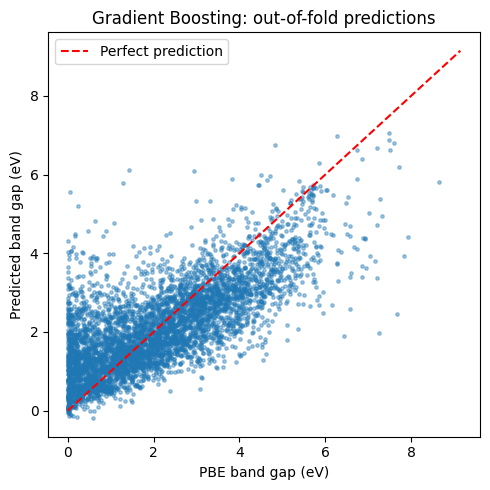

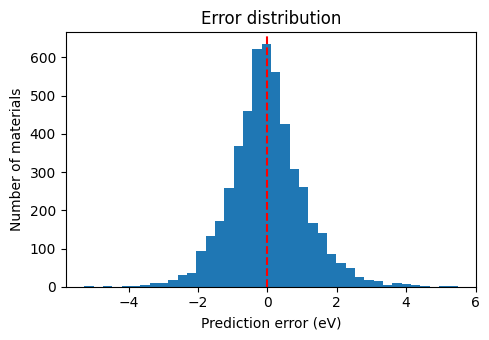

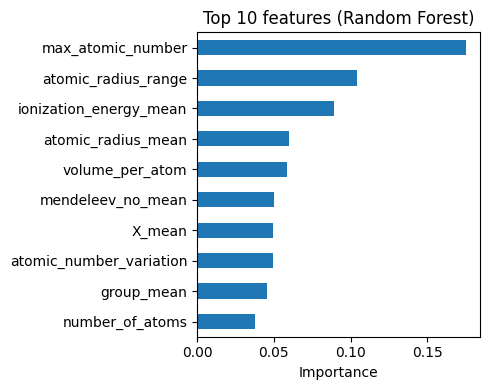

Mean error (bias): 0.000 eV
Within 0.5 eV: 42.7%
Within 1.0 eV: 70.1%


In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.ensemble import (HistGradientBoostingRegressor,
                              RandomForestRegressor)
from sklearn.model_selection import KFold, cross_val_predict

cv = KFold(n_splits=5, shuffle=True, random_state=42)
gb = HistGradientBoostingRegressor(random_state=42)
oof = cross_val_predict(gb, X_new, y_large, cv=cv)
y_true = y_large.values
err = oof - y_true

# Figure 1: predicted vs actual
plt.figure(figsize=(5, 5))
plt.scatter(y_true, oof, s=6, alpha=0.4)
lim = [0, max(y_true.max(), oof.max()) + 0.5]
plt.plot(lim, lim, "r--", label="Perfect prediction")
plt.xlabel("PBE band gap (eV)")
plt.ylabel("Predicted band gap (eV)")
plt.title("Gradient Boosting: out-of-fold predictions")
plt.legend()
plt.tight_layout()
plt.savefig("fig1_predicted_vs_actual.png", dpi=200)
plt.show()

# Figure 2: error distribution
plt.figure(figsize=(5, 3.5))
plt.hist(err, bins=40)
plt.axvline(0, color="r", ls="--")
plt.xlabel("Prediction error (eV)")
plt.ylabel("Number of materials")
plt.title("Error distribution")
plt.tight_layout()
plt.savefig("fig2_error_distribution.png", dpi=200)
plt.show()

# Figure 3: top 10 feature importances (Random Forest)
rf = RandomForestRegressor(n_estimators=100, random_state=42,
                           n_jobs=-1).fit(X_new, y_large)
imp = pd.Series(rf.feature_importances_,
                index=X_new.columns).sort_values().tail(10)
plt.figure(figsize=(5, 4))
imp.plot.barh()
plt.xlabel("Importance")
plt.title("Top 10 features (Random Forest)")
plt.tight_layout()
plt.savefig("fig3_feature_importance.png", dpi=200)
plt.show()

print(f"Mean error (bias): {err.mean():.3f} eV")
print(f"Within 0.5 eV: {(abs(err) < 0.5).mean()*100:.1f}%")
print(f"Within 1.0 eV: {(abs(err) < 1.0).mean()*100:.1f}%")


In [ ]:
from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.ensemble import HistGradientBoostingRegressor

groups = ["-".join(sorted(el.symbol for el in
          get_structure(s).composition.elements))
          for s in larger_sample["structure"]]
print("Unique chemical systems:", len(set(groups)))

sc = cross_validate(
    HistGradientBoostingRegressor(random_state=42),
    X_new, y_large, cv=GroupKFold(n_splits=5), groups=groups,
    scoring=("neg_mean_absolute_error",
             "neg_root_mean_squared_error", "r2"))

mae = -sc["test_neg_mean_absolute_error"]
rmse = -sc["test_neg_root_mean_squared_error"]
r2 = sc["test_r2"]
print(f"MAE : {mae.mean():.4f} ± {mae.std():.4f} eV")
print(f"RMSE: {rmse.mean():.4f} ± {rmse.std():.4f} eV")
print(f"R²  : {r2.mean():.4f} ± {r2.std():.4f}")


Unique chemical systems: 3586
MAE : 0.8501 ± 0.0309 eV
RMSE: 1.1075 ± 0.0268 eV
R²  : 0.4968 ± 0.0238


In [ ]:
from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.ensemble import HistGradientBoostingRegressor

for label, X_ in [("7 original features", X_large),
                  ("32 features", X_new)]:
    sc = cross_validate(
        HistGradientBoostingRegressor(random_state=42),
        X_, y_large, cv=GroupKFold(n_splits=5), groups=groups,
        scoring=("neg_mean_absolute_error",
                 "neg_root_mean_squared_error", "r2"))
    print(label)
    print(f"  MAE  {-sc['test_neg_mean_absolute_error'].mean():.4f}")
    print(f"  RMSE {-sc['test_neg_root_mean_squared_error'].mean():.4f}")
    print(f"  R2   {sc['test_r2'].mean():.4f}")


7 original features
  MAE  0.9584
  RMSE 1.2243
  R2   0.3851
32 features
  MAE  0.8501
  RMSE 1.1075
  R2   0.4968


## Results and Discussion

### Cross-validated results (5,000 materials)

| Experiment | Model | MAE (eV) | RMSE (eV) | R² |
|---|---|---|---|---|
| 7 original features, random 5-fold | Random Forest | 0.8932 | 1.1907 | 0.4200 |
| 32 features, random 5-fold | Random Forest | 0.8045 | 1.0901 | 0.5138 |
| 32 features, random 5-fold | Gradient Boosting | 0.7959 | 1.0624 | 0.5383 |
| 7 original features, chemical-system hold-out | Gradient Boosting | 0.9584 | 1.2243 | 0.3851 |
| 32 features, chemical-system hold-out | Gradient Boosting | 0.8501 | 1.1075 | 0.4968 |

A mean-predictor baseline gave R² ≈ 0, and Ridge regression gave R² = 0.2824 (32 features, random 5-fold).

### Discussion

**Descriptors.** Adding 25 composition-derived descriptors (electronegativity, atomic radius, ionisation energy, periodic-table position and volume per atom) raised R² from 0.420 to 0.514 (Random Forest, random folds) and from 0.385 to 0.497 (Gradient Boosting, chemical-system hold-out). These gains are several times larger than the fold-to-fold variation (R² standard deviation about 0.014 to 0.024).

**Models.** Tree ensembles (R² 0.513 to 0.538) clearly outperformed Ridge regression (0.282), indicating a non-linear relationship between composition and band gap. Differences among the tree ensembles were small, so none is clearly superior. Gradient Boosting was best on R² and RMSE, and Extra Trees on MAE.

**Generalisation.** Holding out whole chemical systems lowered Gradient Boosting performance from R² 0.538 to 0.497 and raised MAE from 0.796 to 0.850 eV. Random splits therefore slightly overstate performance on new chemistry.

**Errors.** Out-of-fold errors are centred on zero but wide: 42.7% of predictions fall within 0.5 eV and 70.1% within 1.0 eV. The model tends to overpredict small band gaps and underpredict large ones.

**Feature importance.** max_atomic_number, atomic_radius_range and ionization_energy_mean were the most important features. This shows predictive association, not causation, and correlated features share importance.

### Limitations

- Roughly half of the variance remains unexplained, so this is an exploratory baseline, not a validated screening tool.
- Features are mostly composition-based and do not capture bonding environments or detailed crystal geometry.
- Targets are PBE-calculated gaps, which underestimate experimental values, and only positive gaps were used.
- Only 5,000 of 106,113 materials were used, and hyperparameters were not tuned.

### Future work

Use the full dataset, add structure-aware descriptors, tune hyperparameters, and test on independent datasets.
